In [1]:
from glyph.ocsr.predict import OCSRPredictor
from glyph.markush.inference import MarkushPredictor

markush = MarkushPredictor(checkpoint="EdisonScientific/MarkushGlyph", base_model="Qwen/Qwen3.5-2B-Base")
markush.predict("markush_m2s_13.png").cxsmiles

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/617 [00:00<?, ?it/s]

"*C1(C*******CC2(*)COC2)COC1 |$R1;;;X;Y;Z;M;Z';Y';X';;;R2;;;;;;$|"

## Dataset

In [2]:
import json
import random
from pathlib import Path

from glyph.markush.eval.benchmark_data import materialize_benchmark
from glyph.markush.inference import _standard_cxsmiles
from glyph.ocsr.eval import load_uspto_benchmark

N_PER_KIND = 50
SEED = 0
DATA = Path("data/mini")
rng = random.Random(SEED)

mol_dir = DATA / "molecules"
mol_dir.mkdir(parents=True, exist_ok=True)
uspto = [r for r in load_uspto_benchmark() if r["smiles"]]

items = []
for r in rng.sample(uspto, N_PER_KIND):
    image = mol_dir / f"{r['id']}.png"
    image.write_bytes(r["image_bytes"])
    items.append({"id": r["id"], "kind": "molecule", "image": str(image), "gt": r["smiles"]})

eval_jsonl, image_root = materialize_benchmark("m2s", DATA / "m2s")
m2s = [json.loads(line) for line in eval_jsonl.read_text().splitlines()]
for r in rng.sample(m2s, N_PER_KIND):
    items.append({
        "id": f"m2s-{r['id']}",
        "kind": "markush",
        "image": str(image_root / r["image"]),
        "gt": _standard_cxsmiles(r["cxsmiles_opt"]),
        "annotation": r["annotation"],
        "prompt": r["prompt"],
    })

print(len(items), "images")

100 images


## Predictions

In [ ]:
from tqdm.auto import tqdm

from glyph.markush.grading import grade
from glyph.ocsr.eval import canonical_smiles, graph_canonical_smiles

ocsr = OCSRPredictor("EdisonScientific/OCSRGlyph")


def score_molecule(prediction, gt):
    pred = canonical_smiles(prediction)
    return {
        "valid": pred is not None,
        "backbone": pred is not None and graph_canonical_smiles(prediction) == graph_canonical_smiles(gt),
        "exact": pred is not None and pred == canonical_smiles(gt),
    }


def score_markush(prediction, annotation):
    s = grade(prediction, annotation)["sample"]
    return {
        "valid": s["valid_pred"],
        "backbone": s["backbone_inchi_match"],
        "exact": s["cxsmiles_full_match"],
    }


results = []
for it in tqdm(items):
    ocsr_pred = ocsr.predict(it["image"])
    if it["kind"] == "molecule":

        m = markush.predict(it["image"])
        ocsr_score = score_molecule(ocsr_pred, it["gt"])
        markush_score = score_molecule(m.cxsmiles.split(" |")[0], it["gt"])
    else:
        m = markush.predict(it["image"], prompt=it["prompt"])
        ocsr_score = score_markush(ocsr_pred, it["annotation"])
        markush_score = score_markush(m.markush_xml, it["annotation"])
    results.append({
        **it,
        "ocsr": ocsr_pred,
        "markush": m.cxsmiles,
        "markush_opt": m.cxsmiles_opt,
        "ocsr_score": ocsr_score,
        "markush_score": markush_score,
    })

(DATA / "results.json").write_text(json.dumps(results, indent=1))

  0%|          | 0/100 [00:00<?, ?it/s]

91817

## Summary

In [10]:
import polars as pl

rows = [
    {"kind": r["kind"], "model": model, **r[f"{key}_score"]}
    for r in results
    for model, key in [("OCSRGlyph", "ocsr"), ("MarkushGlyph", "markush")]
]
(
    pl.DataFrame(rows)
    .group_by("kind", "model", maintain_order=True)
    .agg(pl.len().alias("n"), pl.col("valid", "backbone", "exact").mean().round(2))
)

kind,model,n,valid,backbone,exact
str,str,u32,f64,f64,f64
"""molecule""","""OCSRGlyph""",50,1.0,0.98,0.94
"""molecule""","""MarkushGlyph""",50,0.94,0.46,0.42
"""markush""","""OCSRGlyph""",50,1.0,0.46,0.0
"""markush""","""MarkushGlyph""",50,1.0,0.68,0.64


## Visual comparison

In [ ]:
import base64

import requests
from IPython.display import HTML, display
from rdkit import Chem


def img(data, mime):
    # fixed-height box; large pictures are scaled down to fit, small ones keep their size
    src = base64.b64encode(data).decode()
    return (
        "<div style='height:260px; display:flex; align-items:center; justify-content:center'>"
        f"<img src='data:{mime};base64,{src}' style='max-width:100%; max-height:100%'></div>"
    )


def cdk_svg(smiles):
    return requests.get(
        "https://www.simolecule.com/cdkdepict/depict/bow/svg",
        params={"smi": smiles, "abbr": "off"},
    )


def depict(smiles):
    r = cdk_svg(smiles)
    if r.status_code != 200:
        mol = Chem.MolFromSmiles(smiles)
        if mol is None:
            return f"<code style='word-break:break-all'>{smiles}</code>"
        Chem.Kekulize(mol, clearAromaticFlags=True)
        r = cdk_svg(Chem.MolToCXSmiles(mol))
    return img(r.content, "image/svg+xml")


def score_text(score):
    return ", ".join(f"{name}: {'yes' if ok else 'no'}" for name, ok in score.items())


def show(rs):
    cell = "border:1px solid #ccc; padding:6px; vertical-align:top; width:25%; background:white; color:black"
    html = "<table style='border-collapse:collapse; table-layout:fixed; width:100%'><tr>"
    for header in ["Image", "Ground truth", "OCSRGlyph", "MarkushGlyph"]:
        html += f"<th style='{cell}'>{header}</th>"
    html += "</tr>"
    for r in rs:
        markush_cell = depict(r["markush"]) if r["markush"] else f"<code style='word-break:break-all'>{r['markush_opt']}</code>"
        html += (
            f"<tr><td style='{cell}'><b>{r['id']}</b><br>{img(Path(r['image']).read_bytes(), 'image/png')}</td>"
            f"<td style='{cell}'>{depict(r['gt'])}</td>"
            f"<td style='{cell}'>{depict(r['ocsr'])}<br><small>{score_text(r['ocsr_score'])}</small></td>"
            f"<td style='{cell}'>{markush_cell}<br><small>{score_text(r['markush_score'])}</small></td></tr>"
        )
    display(HTML(html + "</table>"))


def pick(kind, model, exact, n=5):
    return [r for r in results if r["kind"] == kind and r[f"{model}_score"]["exact"] == exact][:n]

### Molecules: MarkushGlyph wrong

Image,Ground truth,OCSRGlyph,MarkushGlyph
US07319101-20080115-C00063,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: yes, exact: no"
US07314693-20080101-C00739,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: no, exact: no"
US07319108-20080115-C00130,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: no, exact: no"
US07317008-20080108-C00033,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: no, exact: no"
US07317032-20080108-C00136,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: no, exact: no"

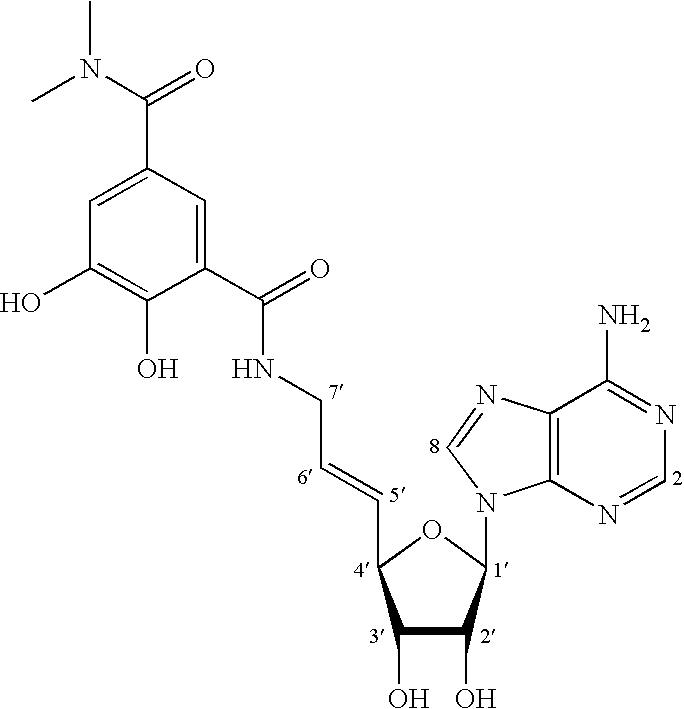
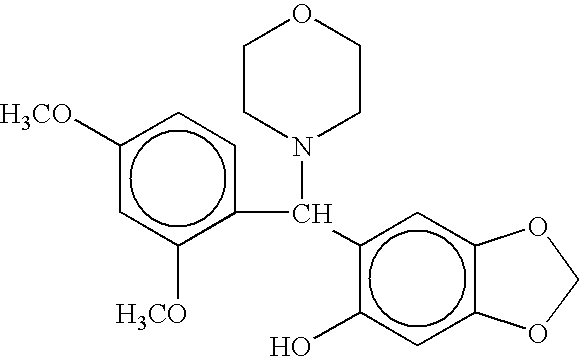
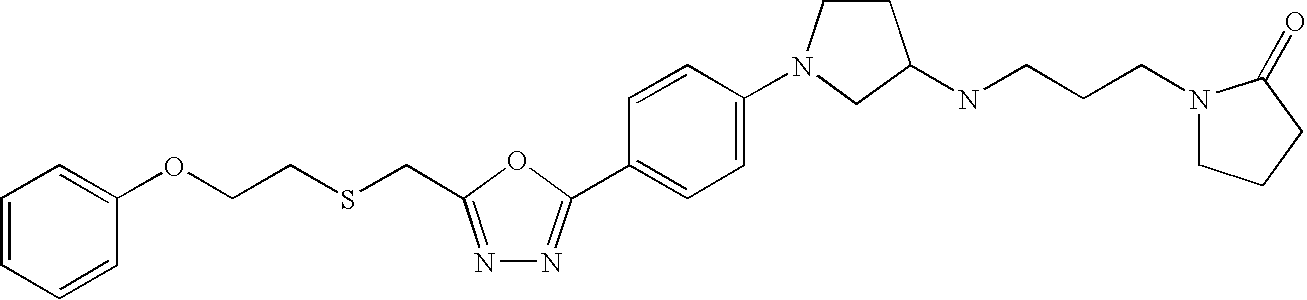
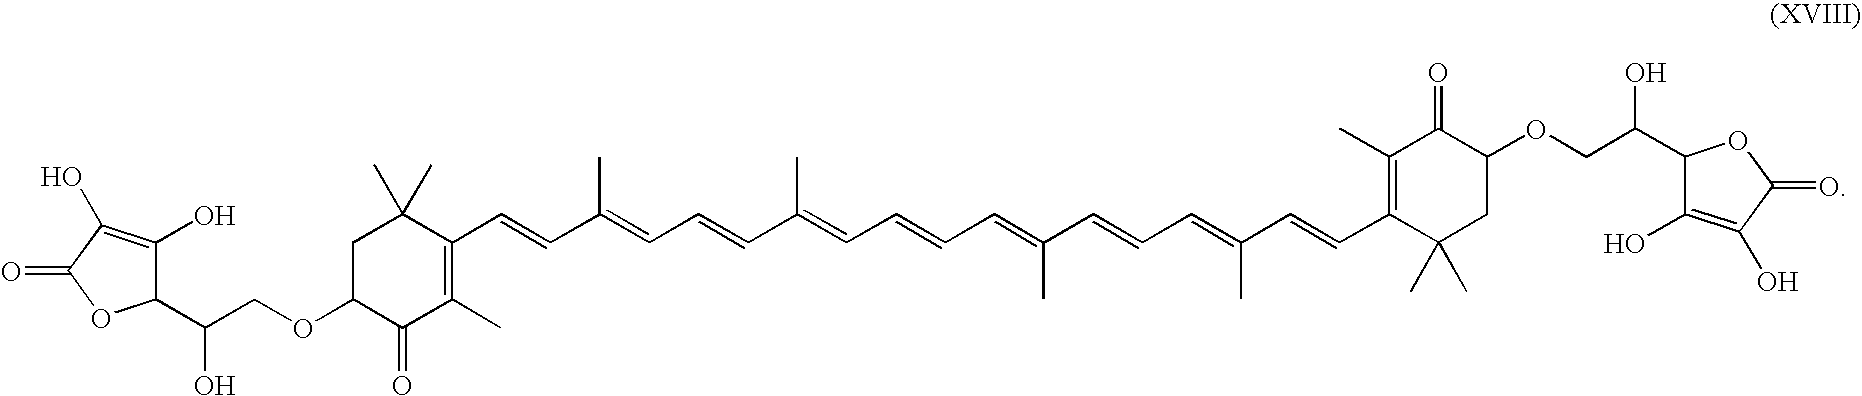
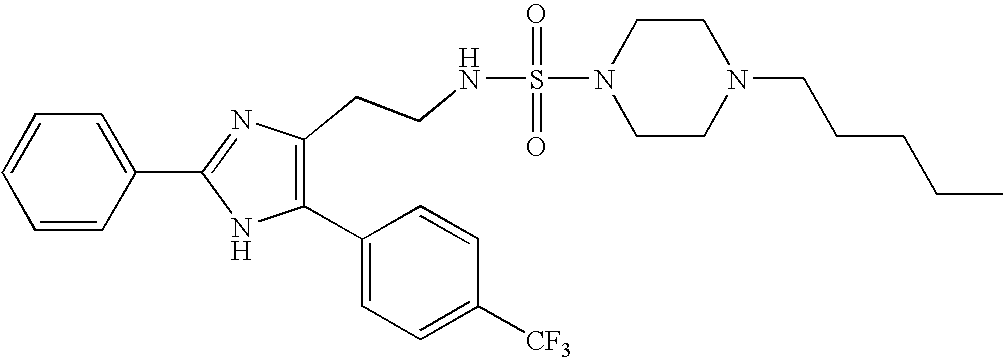

In [18]:
show(pick("molecule", "markush", False))

### Molecules: MarkushGlyph right

Image,Ground truth,OCSRGlyph,MarkushGlyph
US07317110-20080108-C00014,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: yes, exact: yes"
US07314937-20080101-C00240,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: yes, exact: yes"
US07319111-20080115-C00095,,"valid: yes, backbone: yes, exact: yes","valid: yes, backbone: yes, exact: yes"

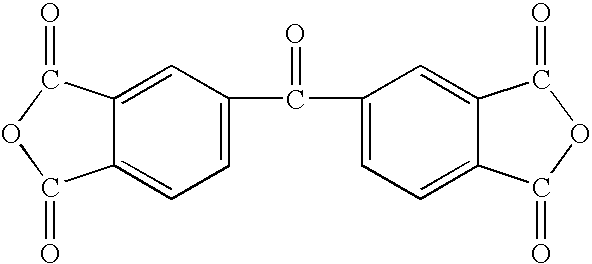
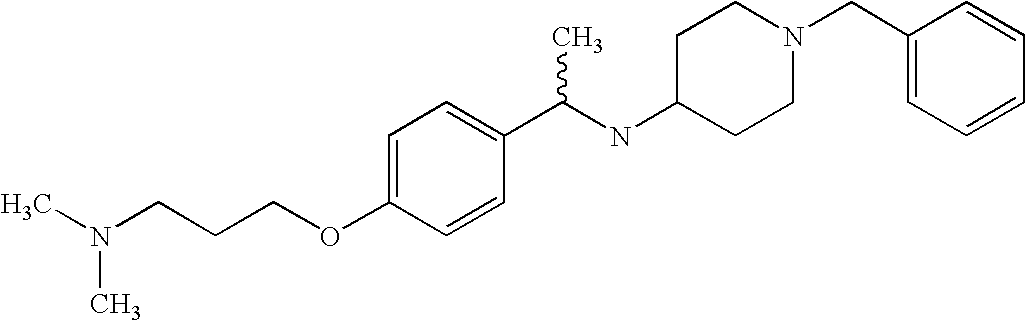
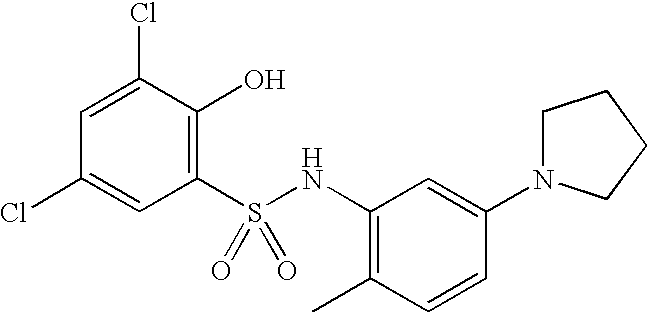

In [19]:
show(pick("molecule", "markush", True, n=3))

### Markush: MarkushGlyph wrong

Image,Ground truth,OCSRGlyph,MarkushGlyph
m2s-63,,"valid: yes, backbone: no, exact: no","valid: yes, backbone: no, exact: no"
m2s-24,,"valid: yes, backbone: yes, exact: no","R1[Bi]([R2])C(R3)(R4)R5valid: yes, backbone: no, exact: no"
m2s-18,,"valid: yes, backbone: no, exact: no","valid: yes, backbone: no, exact: no"
m2s-11,,"valid: yes, backbone: yes, exact: no","valid: yes, backbone: yes, exact: no"
m2s-10,,"valid: yes, backbone: no, exact: no","valid: yes, backbone: no, exact: no"

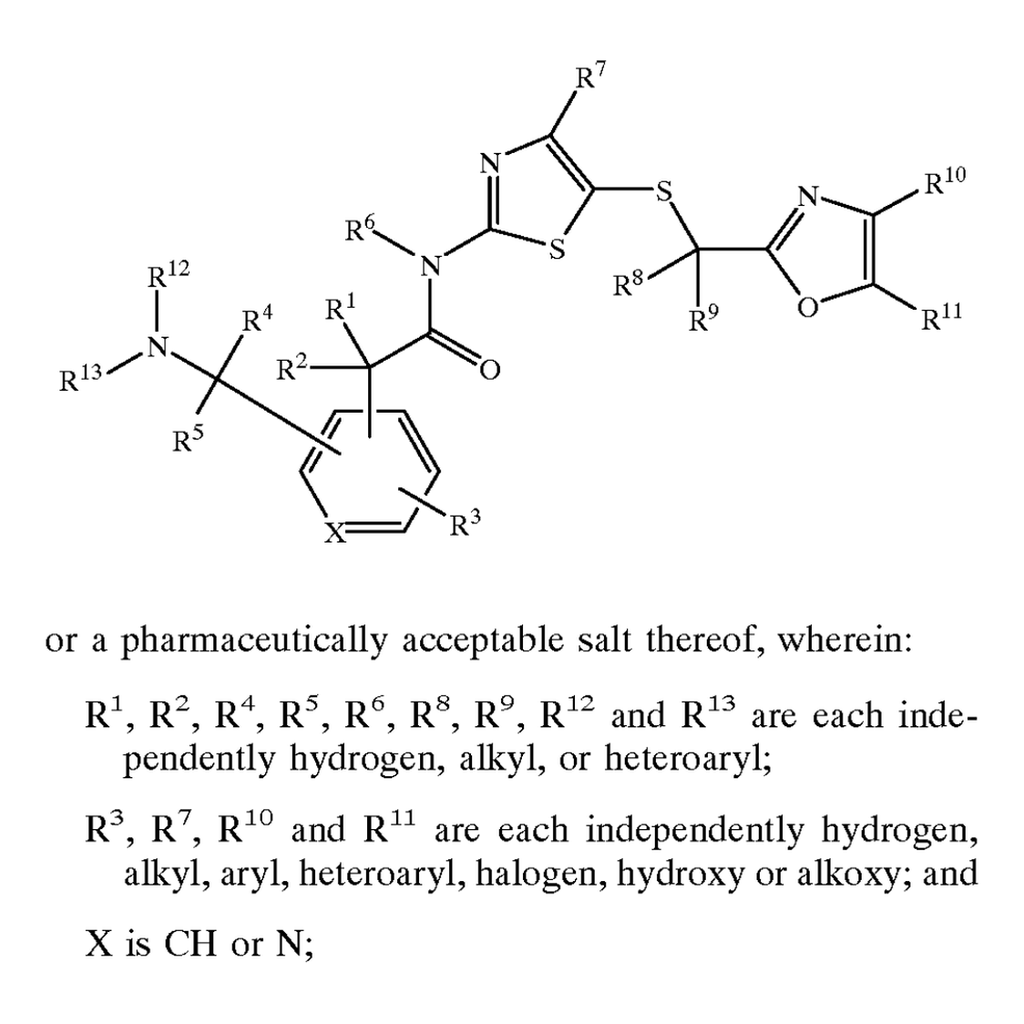
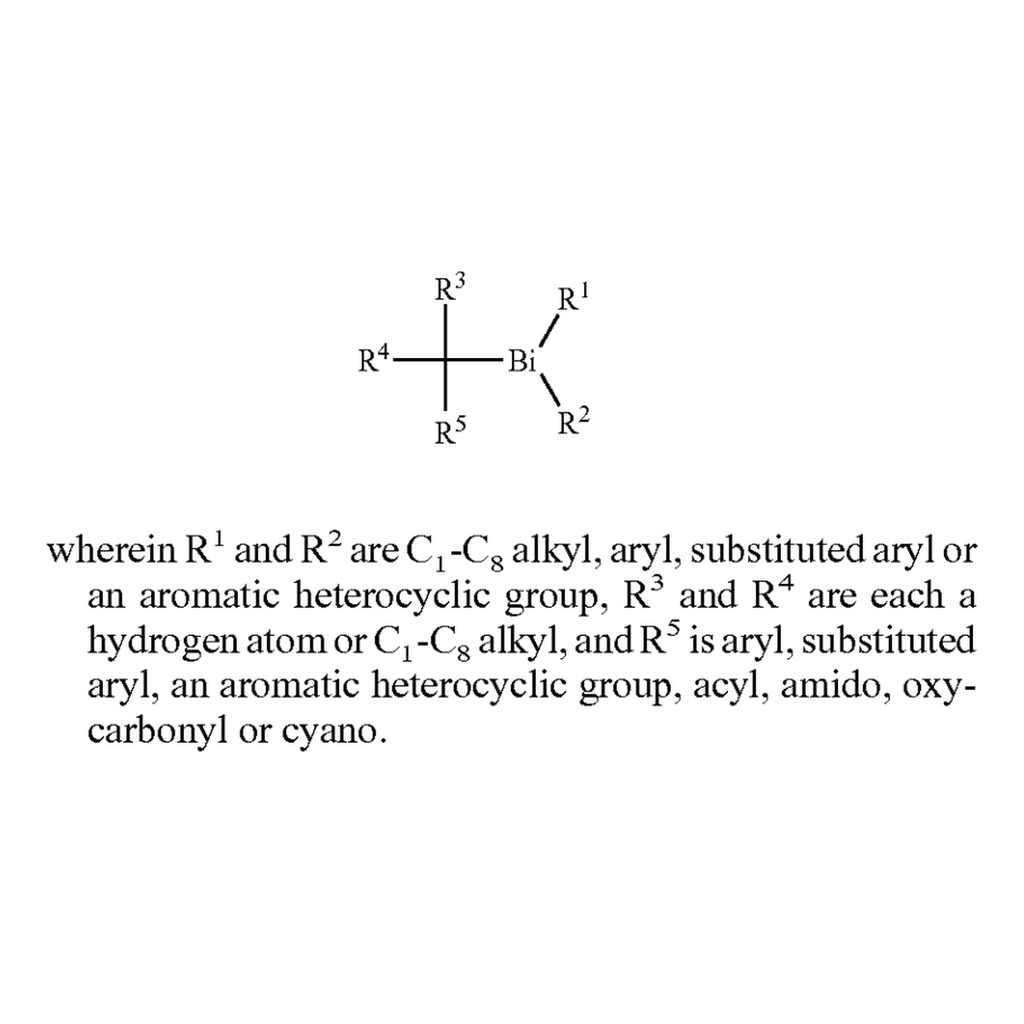
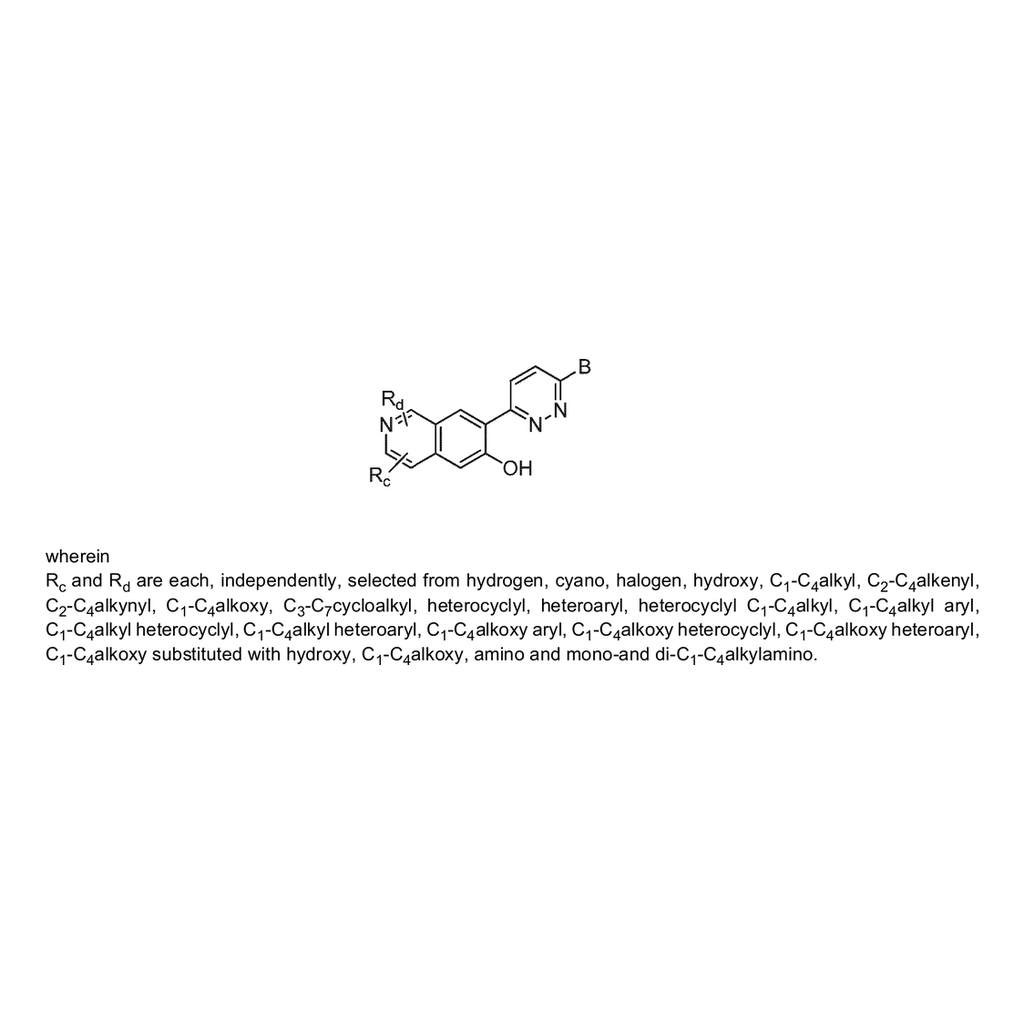
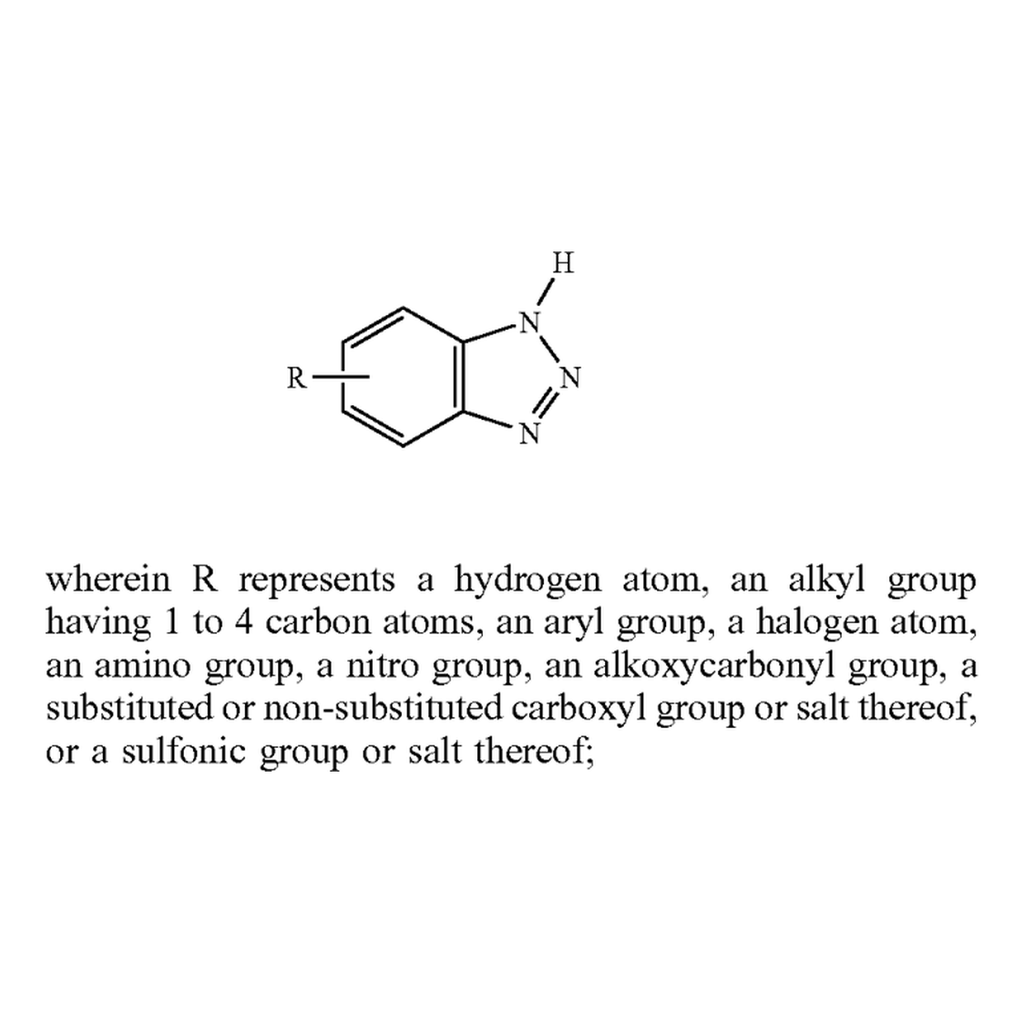
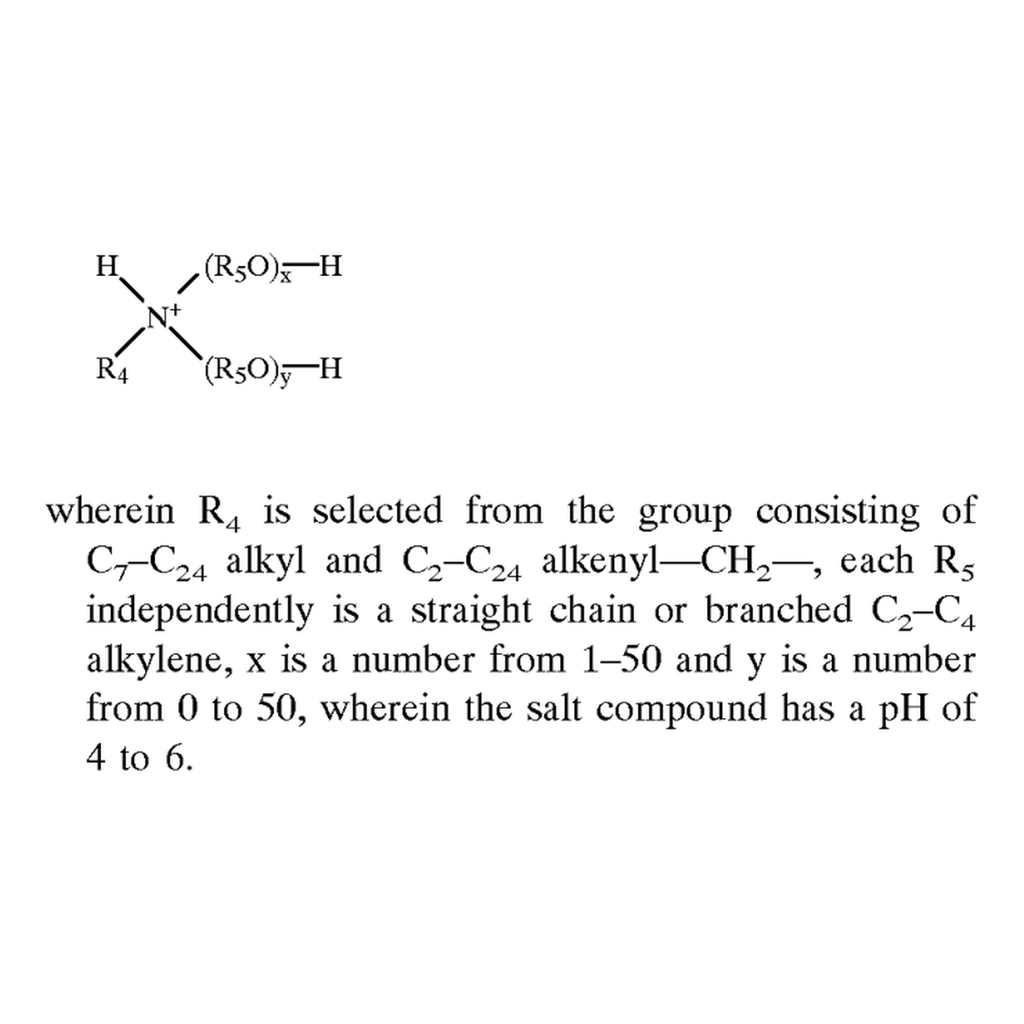

In [20]:
show(pick("markush", "markush", False))

### Markush: MarkushGlyph right

Image,Ground truth,OCSRGlyph,MarkushGlyph
m2s-42,,"valid: yes, backbone: yes, exact: no","valid: yes, backbone: yes, exact: yes"
m2s-31,,"valid: yes, backbone: no, exact: no","valid: yes, backbone: no, exact: yes"
m2s-93,,"valid: yes, backbone: no, exact: no","valid: yes, backbone: yes, exact: yes"
m2s-41,,"valid: yes, backbone: no, exact: no","valid: yes, backbone: yes, exact: yes"
m2s-90,,"valid: yes, backbone: yes, exact: no","valid: yes, backbone: yes, exact: yes"

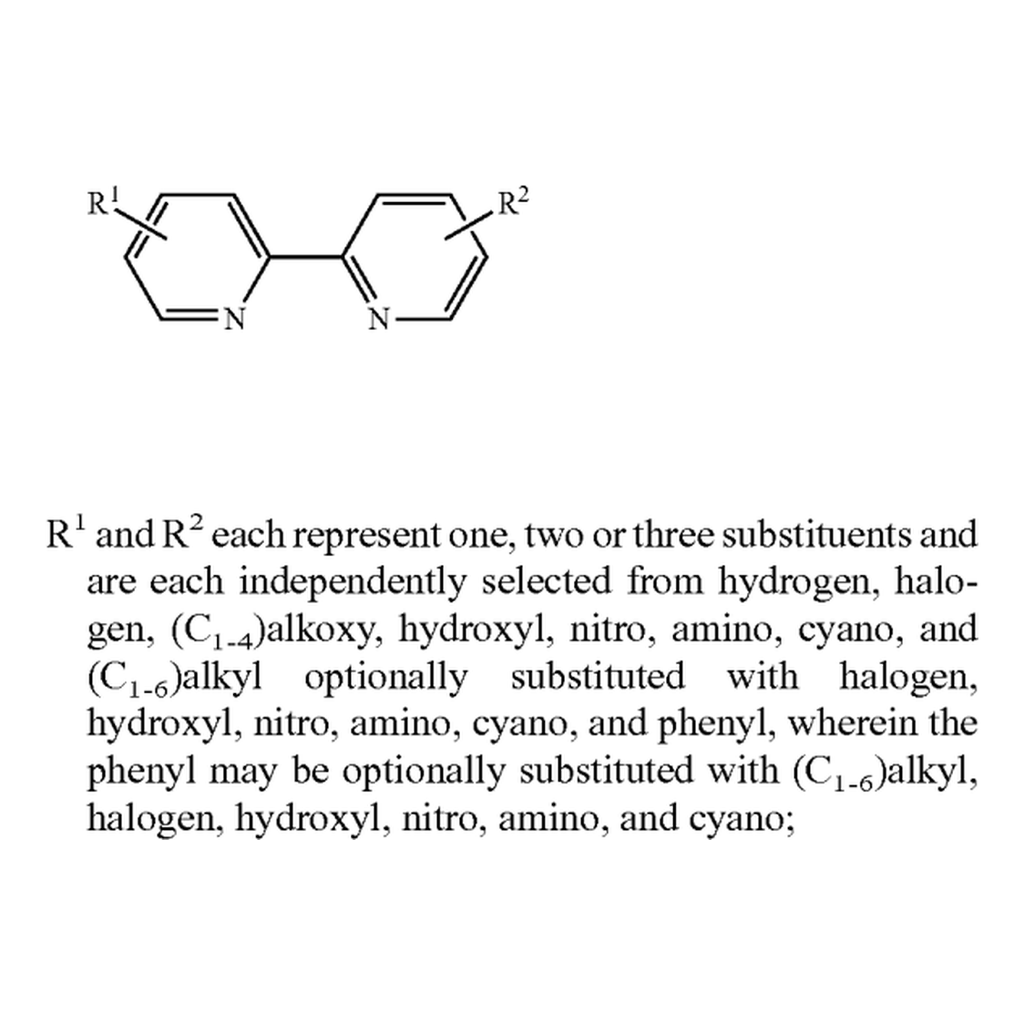
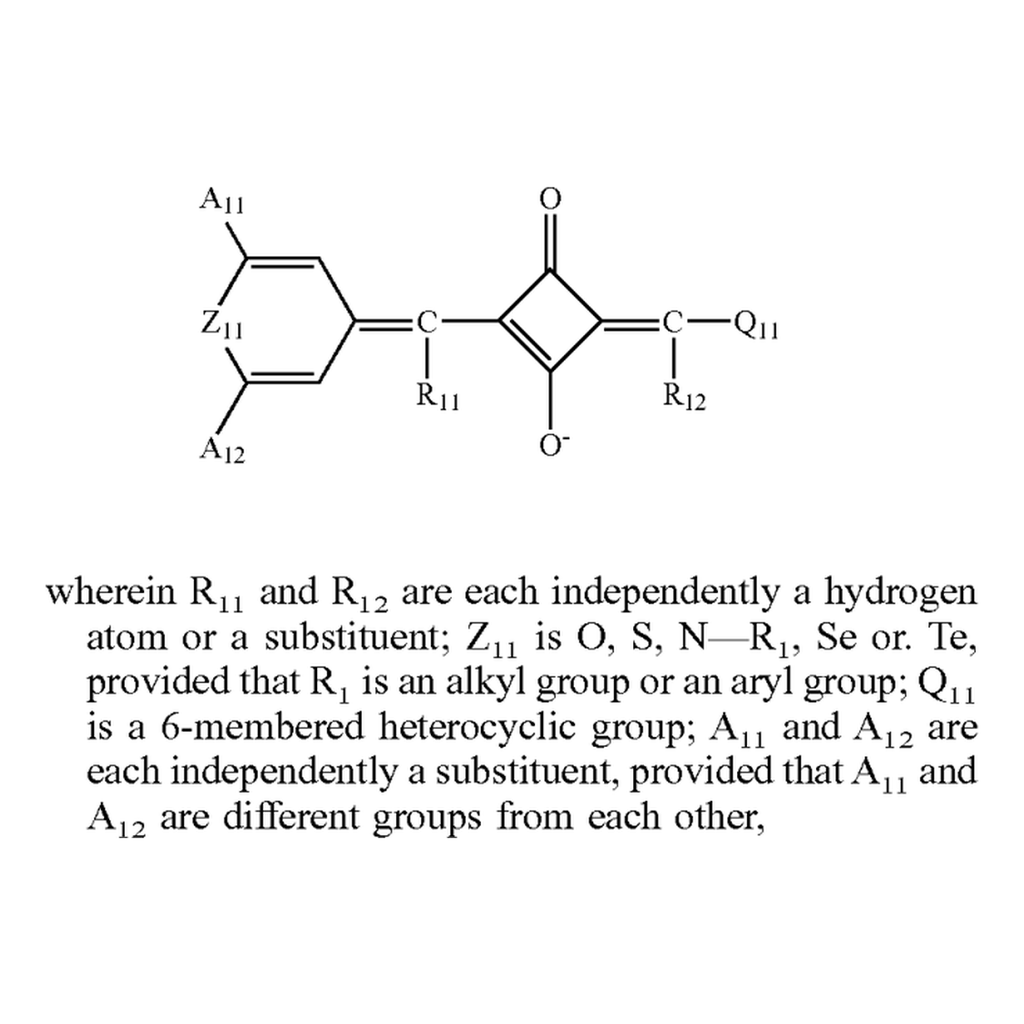
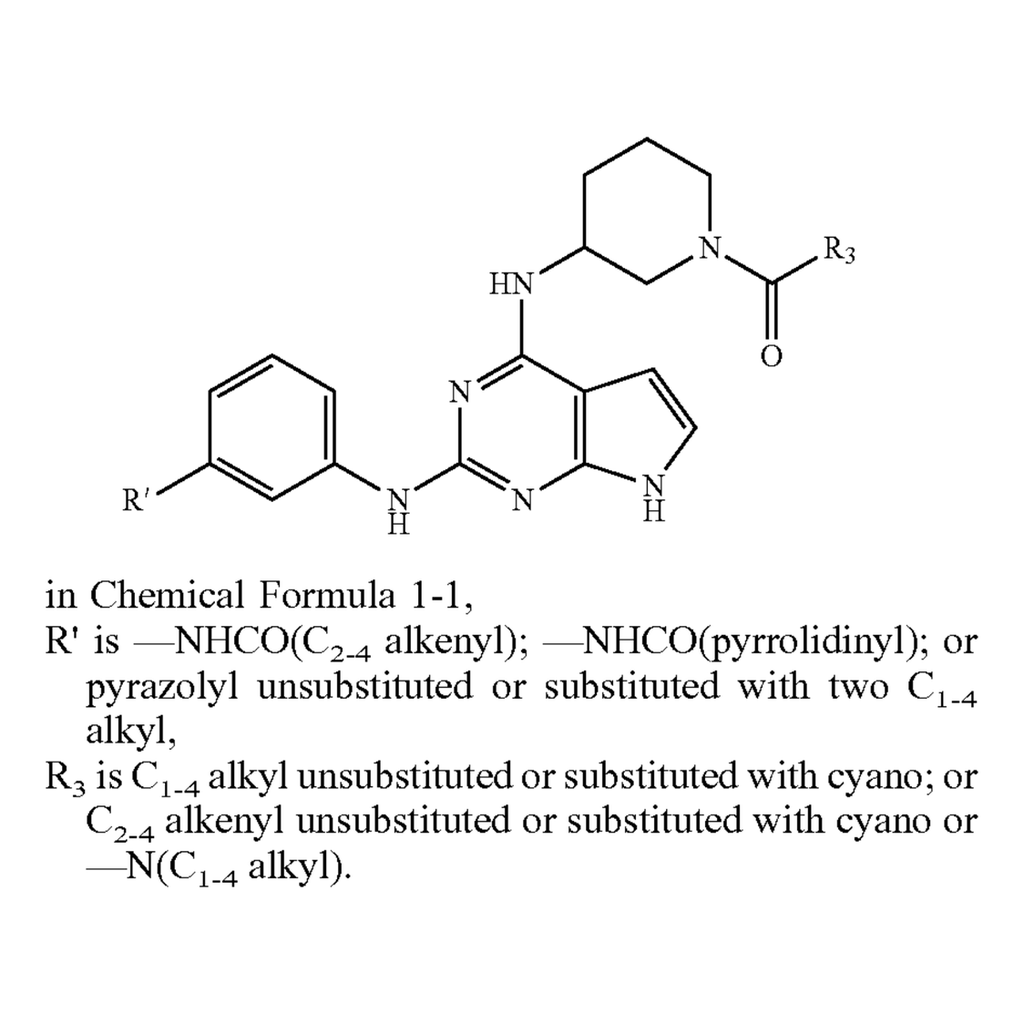
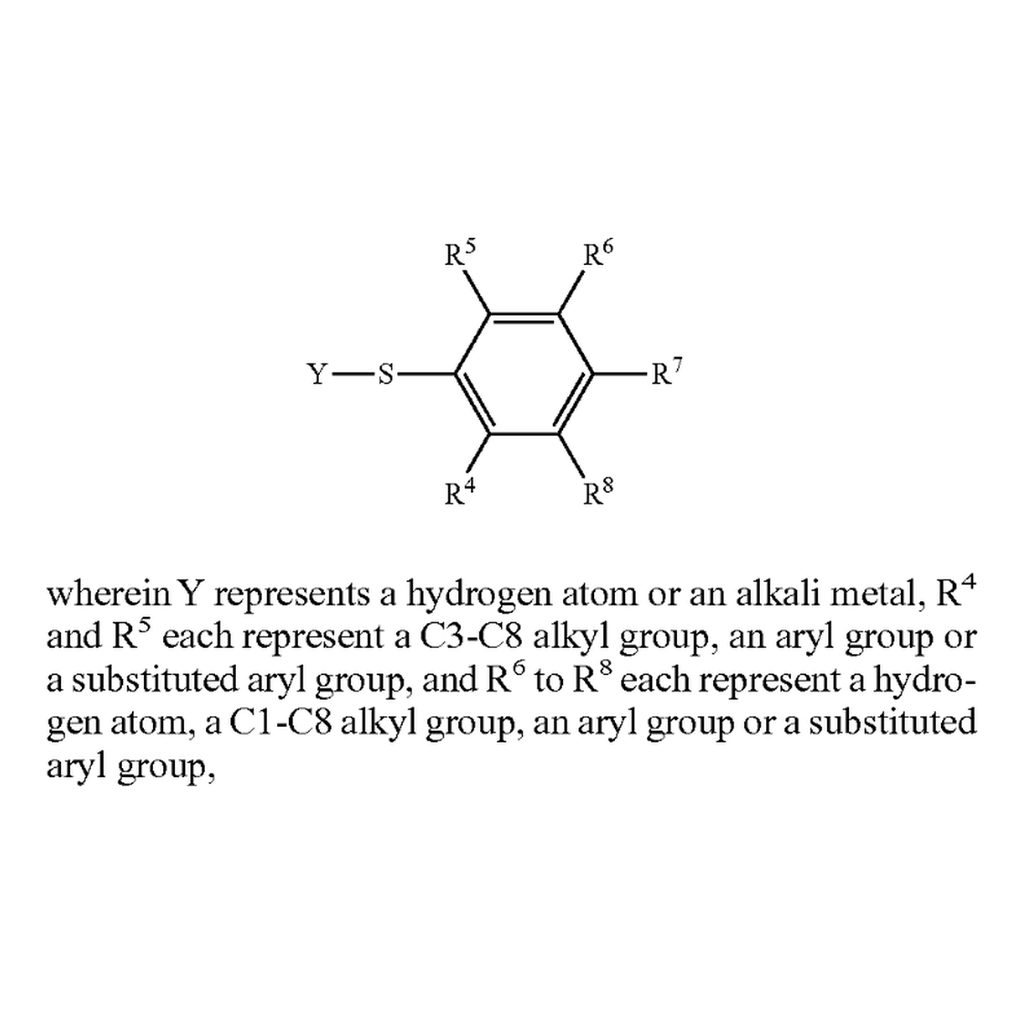
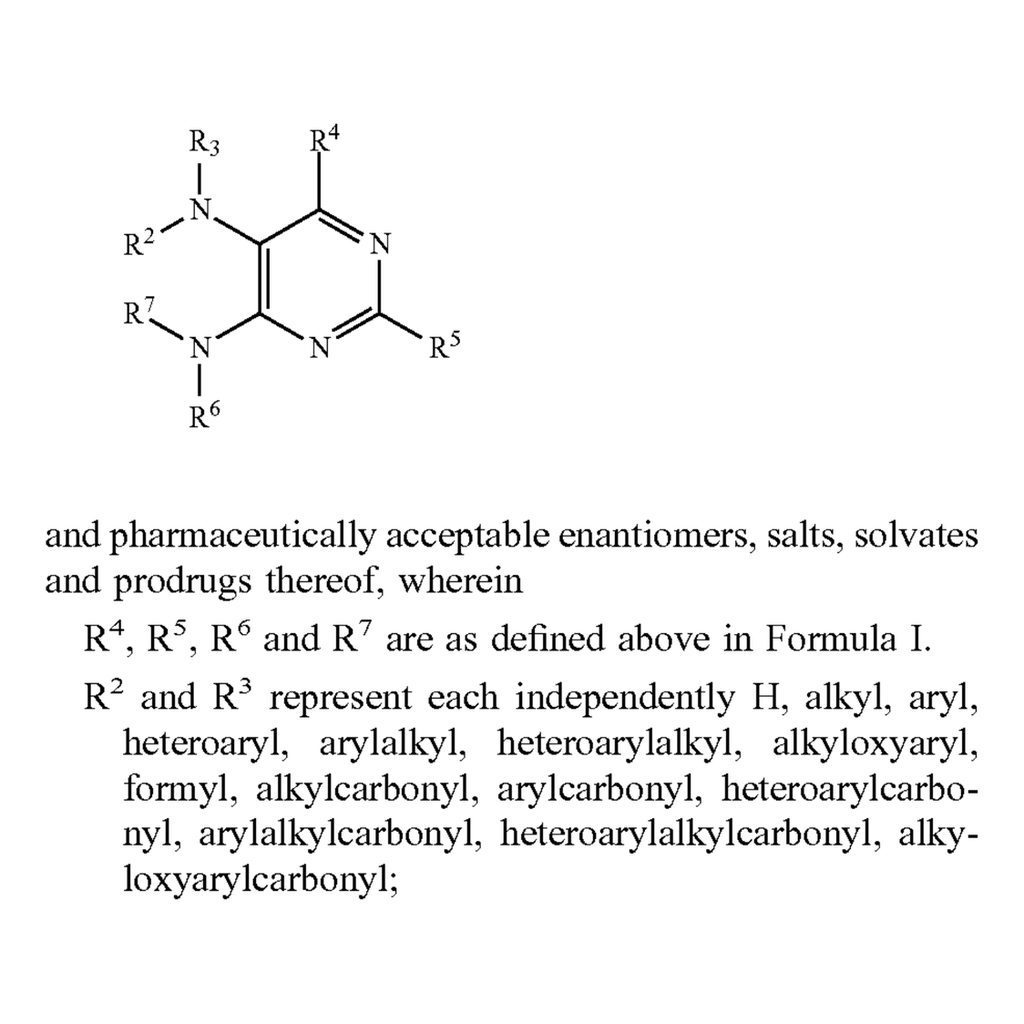

In [21]:
show(pick("markush", "markush", True))